In [15]:

# [1-2: 데이터셋 통계 및 무결성 검사]
# Dataset statistics and RGB-Depth consistency check
#
# 1. S01~S07의 프레임 수, 해상도, FPS, Depth 유효율 계산
# 2. RGB·Depth 파일 번호와 존재 여부 확인
# 3. 타임스탬프 차이(20ms 이내)와 중복 인덱스 검사
# 4. 장면별 통계표와 검증 결과를 CSV로 저장
#
# Uses metadata and file checks without decoding all 7,028 pairs.

from pathlib import Path
import numpy as np
import pandas as pd
import cv2

csv_files = sorted(Path("/kaggle/input").rglob("frames.csv"))
assert len(csv_files) == 7, f"시나리오 수 오류: {len(csv_files)}"

summaries = []
checks = []

for csv_path in csv_files:
    scene_dir = csv_path.parent
    df = pd.read_csv(csv_path, dtype={"frame_id": str})
    scene = scene_dir.name
    n = len(df)

    # RGB·Depth 파일 번호 비교
    rgb_files = sorted((scene_dir / "rgb").glob("*.png"))
    dep_files = sorted((scene_dir / "depth").glob("*.npy"))

    rgb_ids = {p.stem for p in rgb_files}
    dep_ids = {p.stem for p in dep_files}
    csv_ids = set(df["frame_id"].str.zfill(6))

    matched = (
        rgb_ids == dep_ids == csv_ids
        and len(rgb_files) == len(dep_files) == n
        and df["frame_id"].is_unique
    )

    # CSV에 기록된 실제 경로 확인
    paths_ok = all(
        (scene_dir / row.rgb_path).is_file()
        and (scene_dir / row.depth_path).is_file()
        for row in df.itertuples()
    )

    # 첫 프레임을 실제로 읽어 해상도와 자료형 확인
    first = df.iloc[0]
    rgb = cv2.imread(str(scene_dir / first["rgb_path"]))
    depth = np.load(scene_dir / first["depth_path"], allow_pickle=False)

    shape_ok = (
        rgb is not None
        and rgb.shape == (720, 1280, 3)
        and rgb.dtype == np.uint8
        and depth.shape == (720, 1280)
        and depth.dtype == np.float32
    )

    # RGB·Depth 센서 시간차와 기록된 값 비교
    rgb_ns = df["rgb_header_ns"].to_numpy(dtype=np.int64)
    dep_ns = df["depth_header_ns"].to_numpy(dtype=np.int64)
    delta_ms = (dep_ns - rgb_ns) / 1e6

    time_ok = np.all(np.abs(delta_ms) <= 20)
    recorded = df["depth_minus_rgb_ms"].to_numpy(dtype=float)
    timestamp_ok = np.all(np.abs(delta_ms - recorded) <= 0.001)

    # 원본 프레임 중복 여부
    duplicate_ok = (
        df["source_rgb_index"].is_unique
        and df["source_depth_index"].is_unique
    )

    # 실제 RGB 타임스탬프 기준 FPS
    dt = np.diff(rgb_ns) / 1e9
    valid_dt = dt[dt > 0]
    fps = 1 / np.median(valid_dt) if len(valid_dt) else np.nan

    ratios = df["depth_valid_pixel_ratio"].astype(float)
    ratio_ok = ratios.between(0, 1).all()

    passed = all([
        matched, paths_ok, shape_ok,
        time_ok, timestamp_ok, duplicate_ok, ratio_ok
    ])

    summaries.append({
        "scene": scene,
        "frames": n,
        "resolution": "1280x720",
        "fps": round(fps, 2),
        "duration_sec": round((rgb_ns[-1] - rgb_ns[0]) / 1e9, 2),
        "depth_mean_valid_pct": round(ratios.mean() * 100, 2),
        "depth_min_valid_pct": round(ratios.min() * 100, 2)
    })

    checks.append({
        "scene": scene,
        "frame_ids_match": matched,
        "paths_exist": paths_ok,
        "sample_format_ok": shape_ok,
        "timestamp_within_20ms": time_ok,
        "timestamp_metadata_match": timestamp_ok,
        "no_duplicate_source_indices": duplicate_ok,
        "valid_ratio_range_ok": ratio_ok,
        "passed": passed
    })

summary_df = pd.DataFrame(summaries)
check_df = pd.DataFrame(checks)

out = Path("/kaggle/working")
out.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(out / "scene_summary.csv", index=False, encoding="utf-8-sig")
check_df.to_csv(out / "data_checks.csv", index=False)

print("=== 장면별 통계 ===")
display(summary_df)

print("=== 데이터 검증 ===")
display(check_df)

print("전체 대응 프레임:", summary_df["frames"].sum())
print("전체 검증 통과:", check_df["passed"].all())


=== 장면별 통계 ===


,scene,frames,resolution,fps,duration_sec,depth_mean_valid_pct,depth_min_valid_pct
0,S01_meat_multi_static,1054,1280x720,30.0,35.13,47.87,45.75
1,S02_meat_single_static,1069,1280x720,30.0,35.60,56.45,55.19
2,S03_meat_single_moving,934,1280x720,30.0,31.20,58.44,52.03
3,S04_meat_multi_moving,1062,1280x720,30.0,35.53,48.55,41.10
4,S05_icebox_static,1057,1280x720,30.0,35.43,47.30,41.96
5,S06_icebox_moving,992,1280x720,30.0,33.03,49.22,42.40
6,S07_warehouse_entry_30s,860,1280x720,30.0,28.67,55.05,40.39


=== 데이터 검증 ===


,scene,frame_ids_match,paths_exist,sample_format_ok,timestamp_within_20ms,timestamp_metadata_match,no_duplicate_source_indices,valid_ratio_range_ok,passed
0,S01_meat_multi_static,True,True,True,True,True,True,True,True
1,S02_meat_single_static,True,True,True,True,True,True,True,True
2,S03_meat_single_moving,True,True,True,True,True,True,True,True
3,S04_meat_multi_moving,True,True,True,True,True,True,True,True
4,S05_icebox_static,True,True,True,True,True,True,True,True
5,S06_icebox_moving,True,True,True,True,True,True,True,True
6,S07_warehouse_entry_30s,True,True,True,True,True,True,True,True


전체 대응 프레임: 7028
전체 검증 통과: True


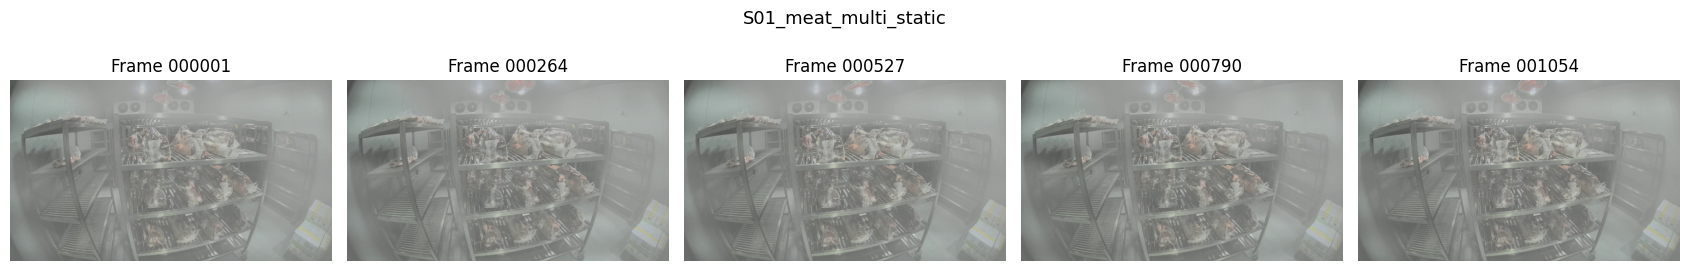

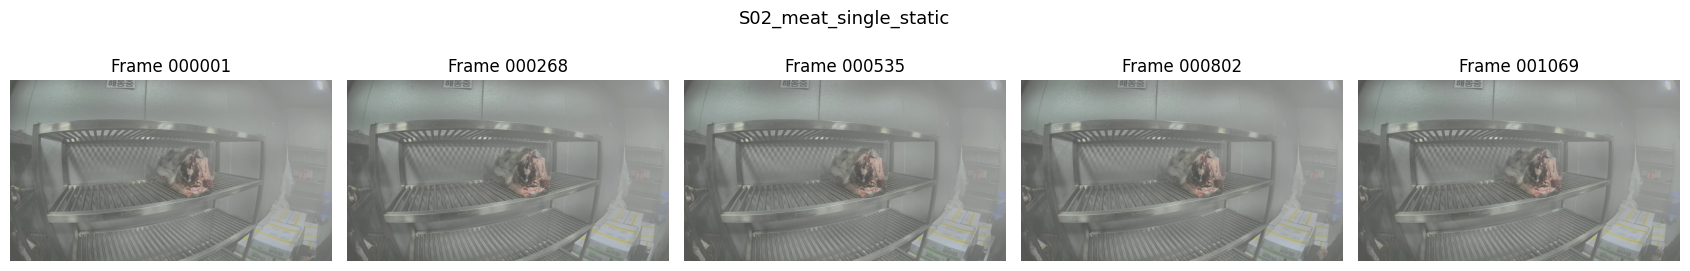

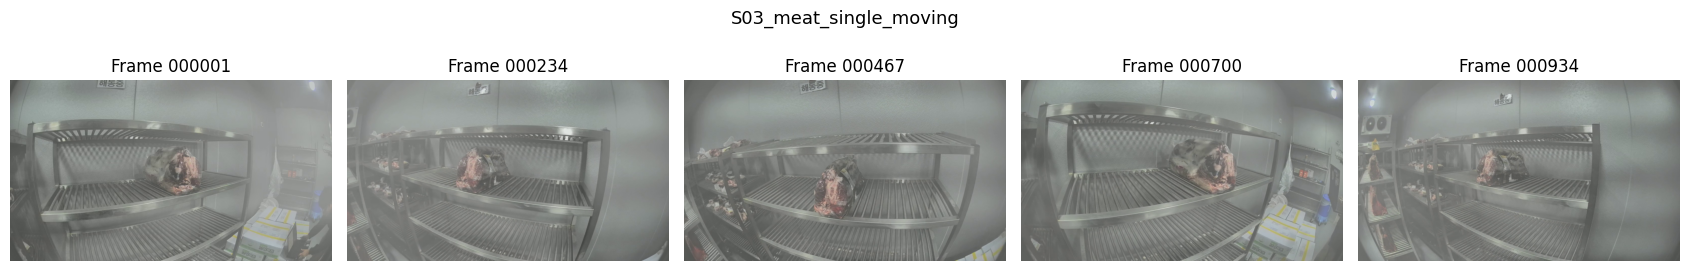

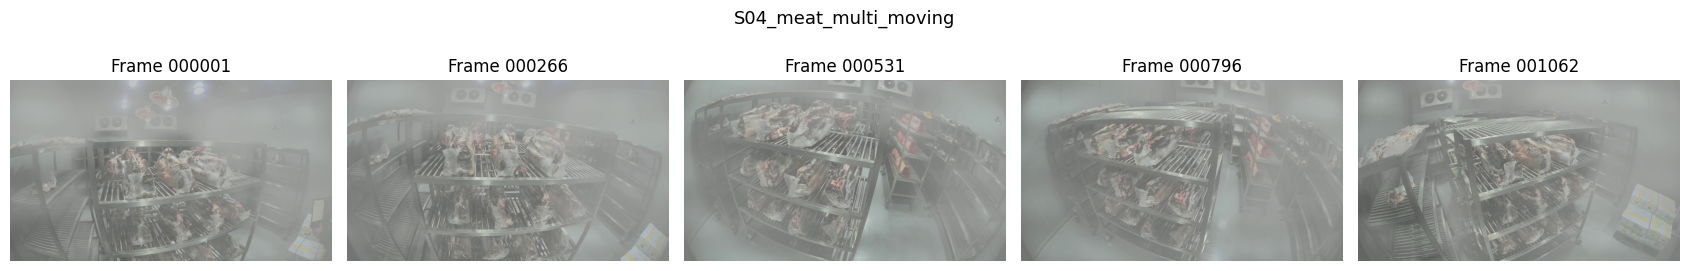

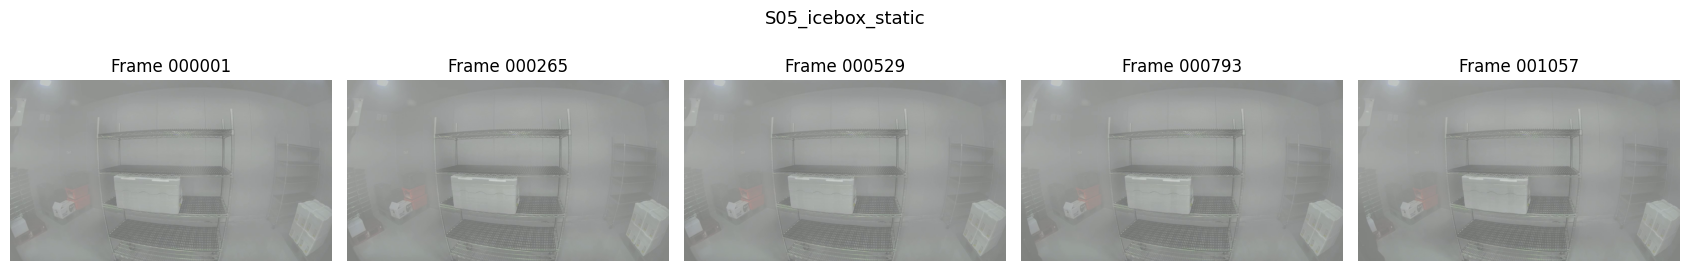

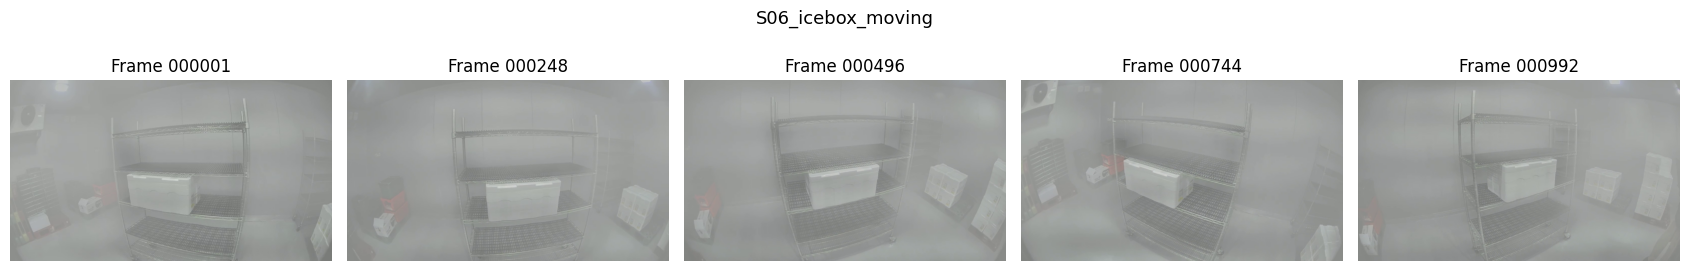

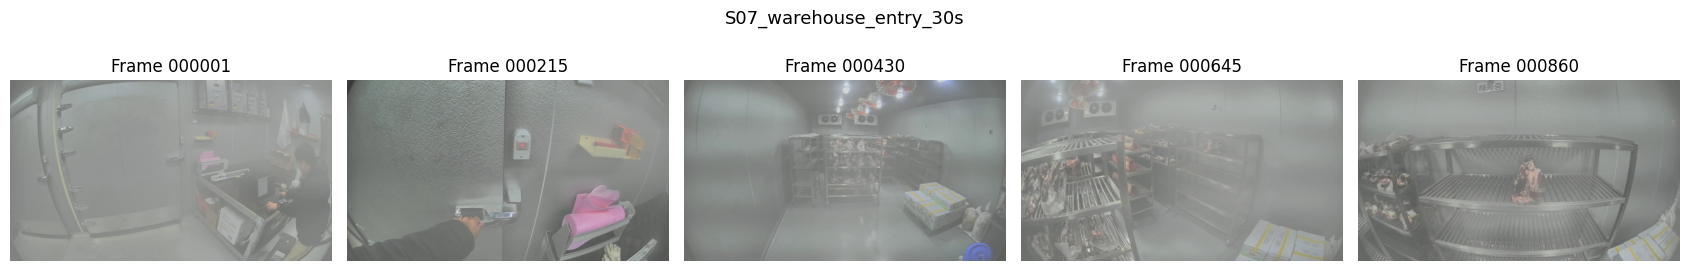

In [16]:

# [1-2: 안개 농도 및 맑은 장면 육안 확인]
# Visual inspection of fog severity and clear-scene presence
#
# 시나리오별 시작·25%·50%·75%·마지막 프레임을 표시한다.
# 안개 농도(옅음/중간/짙음)와 맑은 장면 유무를 육안으로 확인한다.
#
# Display five representative frames per scene to visually
# inspect fog severity and check for clear scenes.

import matplotlib.pyplot as plt

for csv_path in csv_files:
    scene_dir = csv_path.parent
    frames = sorted((scene_dir / "rgb").glob("*.png"))

    indices = np.linspace(0, len(frames) - 1, 5, dtype=int)
    fig, axes = plt.subplots(1, 5, figsize=(17, 3))

    for ax, idx in zip(axes, indices):
        path = frames[idx]
        img = cv2.imread(str(path))

        if img is None:
            ax.set_title("Read error")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            ax.set_title(f"Frame {path.stem}")

        ax.axis("off")

    fig.suptitle(scene_dir.name, fontsize=13)
    plt.tight_layout()
    plt.show()


In [17]:

# [1-2: 장면별 육안 분류 결과 저장]
# Save scene-level visual inspection results
#
# 대표 프레임 35장을 기준으로 안개 농도를 기록한다.
# 맑은 장면은 대표 프레임에서 확인되지 않았으나,
# 전체 프레임에 없다고 확정한 것은 아니다.
#
# Record fog levels based on 35 sampled images.
# No clearly fog-free scene was observed in the sample;
# this is not a full-frame absence verification.

fog_df = pd.DataFrame({
    "scene": ["S01", "S02", "S03", "S04", "S05", "S06", "S07"],
    "fog_level": [
        "medium", "light", "light", "medium",
        "heavy", "heavy", "medium"
    ],
    "clear_scene_observed": [False] * 7,
    "frames_reviewed": [5] * 7
})

fog_df.to_csv(
    "/kaggle/working/fog_levels.csv",
    index=False,
    encoding="utf-8-sig"
)

display(fog_df)
print("fog_levels.csv 저장 완료")


,scene,fog_level,clear_scene_observed,frames_reviewed
0,S01,medium,False,5
1,S02,light,False,5
2,S03,light,False,5
3,S04,medium,False,5
4,S05,heavy,False,5
5,S06,heavy,False,5
6,S07,medium,False,5


fog_levels.csv 저장 완료


In [18]:
%%writefile /kaggle/working/dataset.py

"""Gemini RGB-D dataset loader for the fogdet project.

The loader reads scenario metadata once, and only loads images on demand.
Images are returned as OpenCV BGR uint8 arrays, suitable for
Identity/CLAHE/DCP/LearnedDefog's common interface.

Usage::

    from dataset import GeminiDataset
    data = GeminiDataset()  # finds frames.csv under /kaggle/input
    bgr, depth, meta = data.load('S01', 1)
    for bgr, meta in data.iter_frames('S01', include_depth=False):
        ...
"""

from __future__ import annotations

import csv
from pathlib import Path
from typing import Iterator, Optional, Union

import cv2
import numpy as np

PathLike = Union[str, Path]


class GeminiDataset:
    """Read paired RGB/Depth data from S01–S07 without loading all frames into RAM.

    Parameters
    ----------
    root:
        Directory to search for scene-level ``frames.csv`` files.
        Kaggle's ``/kaggle/input`` is used by default. May also point
        directly to the dataset directory containing S01... folders.

    Notes
    -----
    ``frame_number`` is the 1-based *row position* in ``frames.csv``.
    The returned metadata contains the dataset's original ``frame_id``.
    """

    def __init__(self, root: PathLike = "/kaggle/input") -> None:
        self.root = Path(root).expanduser()
        if not self.root.is_dir():
            raise FileNotFoundError(f"Dataset root does not exist: {self.root}")

        self.scenes: dict[str, dict] = {}
        for csv_path in sorted(self.root.rglob("frames.csv")):
            # Only accept scene-level CSVs with IDs such as S01, S02, etc.
            scene_dir = csv_path.parent
            scene_id = scene_dir.name.split("_", 1)[0].upper()
            if not (len(scene_id) == 3 and scene_id[0] == "S" and scene_id[1:].isdigit()):
                continue
            with csv_path.open("r", encoding="utf-8-sig", newline="") as handle:
                reader = csv.DictReader(handle)
                if not reader.fieldnames or not {"rgb_path", "depth_path"}.issubset(reader.fieldnames):
                    raise ValueError(f"Missing rgb_path/depth_path in {csv_path}")
                rows = list(reader)
            if not rows:
                raise ValueError(f"Empty frames.csv: {csv_path}")
            if scene_id in self.scenes:
                raise ValueError(
                    f"Duplicate scene {scene_id}: {self.scenes[scene_id]['path']} and {scene_dir}. "
                    "Specify a more precise root."
                )
            self.scenes[scene_id] = {"path": scene_dir, "rows": rows}

        if not self.scenes:
            raise FileNotFoundError(f"No scenario frames.csv found under {self.root}")

    @property
    def scene_ids(self) -> list[str]:
        """Sorted IDs, e.g. ['S01', ..., 'S07']."""
        return sorted(self.scenes)

    def __len__(self) -> int:
        """Total paired RGB-D frame count across scenes."""
        return sum(len(info["rows"]) for info in self.scenes.values())

    def frame_count(self, scene_id: str) -> int:
        """Number of paired frames in a scene."""
        return len(self._scene(scene_id)["rows"])

    def _scene(self, scene_id: str) -> dict:
        key = scene_id.upper()
        if key not in self.scenes:
            raise KeyError(f"Unknown scene {scene_id!r}; available: {self.scene_ids}")
        return self.scenes[key]

    def _row_and_dir(self, scene_id: str, frame_number: int) -> tuple[dict, Path]:
        scene = self._scene(scene_id)
        if not isinstance(frame_number, int) or not 1 <= frame_number <= len(scene["rows"]):
            raise IndexError(
                f"Invalid frame_number {frame_number!r} for {scene_id}; "
                f"expected 1..{len(scene['rows'])}"
            )
        return scene["rows"][frame_number - 1], scene["path"]

    def load(
        self, scene_id: str, frame_number: int, *, include_depth: bool = True
    ) -> tuple:
        """Load a numbered paired frame (1-based row position).

        When include_depth=True: returns ``(bgr, depth_m, metadata)``.
        When include_depth=False: returns ``(bgr, metadata)``.
        BGR: uint8 HxWx3; depth: float32 HxW, meters, zero invalid.
        """
        row, scene_dir = self._row_and_dir(scene_id, frame_number)
        rgb_path = scene_dir / row["rgb_path"]
        bgr = cv2.imread(str(rgb_path), cv2.IMREAD_COLOR)
        if bgr is None:
            raise FileNotFoundError(f"Unable to read RGB image: {rgb_path}")
        if bgr.ndim != 3 or bgr.shape[2] != 3 or bgr.dtype != np.uint8:
            raise ValueError(f"RGB image has unexpected shape/type: {rgb_path}")

        metadata = dict(row)
        metadata.update({
            "scene_id": scene_id.upper(),
            "frame_number": frame_number,
            "rgb_file": str(rgb_path),
        })
        if not include_depth:
            return bgr, metadata

        depth_path = scene_dir / row["depth_path"]
        try:
            depth_m = np.load(depth_path, allow_pickle=False)
        except (OSError, ValueError) as exc:
            raise OSError(f"Unable to read Depth array: {depth_path}") from exc
        if depth_m.shape != bgr.shape[:2] or depth_m.dtype != np.float32:
            raise ValueError(
                f"Depth shape/type mismatch: {depth_path}; "
                f"got {depth_m.shape}/{depth_m.dtype}, expected {bgr.shape[:2]}/float32"
            )
        metadata["depth_file"] = str(depth_path)
        return bgr, depth_m, metadata

    def iter_frames(
        self, scene_id: Optional[str] = None, *, include_depth: bool = False
    ) -> Iterator[tuple]:
        """Yield frames lazily in ascending scene and frame order.

        If scene_id is None, iterates over all scenes. RGB-only iteration
        is the default because dehazing takes BGR images as input.
        """
        ids = [scene_id.upper()] if scene_id is not None else self.scene_ids
        for sid in ids:
            for n in range(1, self.frame_count(sid) + 1):
                yield self.load(sid, n, include_depth=include_depth)


if __name__ == "__main__":
    dataset = GeminiDataset()
    print("Scene IDs:", dataset.scene_ids)
    print("Total paired frames:", len(dataset))
    for sid in dataset.scene_ids:
        print(f"  {sid}: {dataset.frame_count(sid)} pairs")
    bgr, depth, meta = dataset.load(dataset.scene_ids[0], 1)
    print("Sample BGR:", bgr.shape, bgr.dtype)
    print("Sample Depth:", depth.shape, depth.dtype)
    print("Sample metadata frame_id:", meta.get("frame_id"))


Overwriting /kaggle/working/dataset.py


In [19]:
# [데이터 로더 기본 동작 테스트]
# dataset.py를 정상적으로 불러올 수 있는지 확인한다.
# GeminiDataset 객체를 생성하고 S01~S07 시나리오 목록과
# 전체 7,028개 대응 프레임을 정확하게 인식하는지 점검한다.
# 또한 S01의 첫 번째 RGB·Depth·메타데이터를 불러와
# 이미지 크기, 자료형, 프레임 ID를 확인한다.
#
# [Data Loader Basic Functionality Test]
# Verify that dataset.py can be imported successfully.
# Initialize GeminiDataset and check whether all seven scenarios
# and 7,028 paired frames are correctly recognized.
# Load the first RGB-Depth sample and its metadata from S01
# to verify image shapes, data types, and frame ID.

from dataset import GeminiDataset

dataset = GeminiDataset()

print("시나리오:", dataset.scene_ids)
print("전체 프레임:", len(dataset))

rgb, depth, metadata = dataset.load("S01", 1)

print("RGB:", rgb.shape, rgb.dtype)
print("Depth:", depth.shape, depth.dtype)
print("프레임 ID:", metadata["frame_id"])

시나리오: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07']
전체 프레임: 7028
RGB: (720, 1280, 3) uint8
Depth: (720, 1280) float32
프레임 ID: 000001


In [20]:
# [데이터 로더 프레임 순회 테스트]
# dataset.py의 iter_frames() 기능이 정상적으로 작동하는지 확인한다.
# S01 시나리오의 처음 5개 RGB 프레임을 순서대로 불러오고,
# 각 프레임의 ID, 이미지 크기, 자료형을 출력한다.
# Depth 로딩은 생략하여 RGB만 필요한 dehazing 알고리즘에서
# 불필요한 데이터 로딩 없이 사용할 수 있는지 점검한다.
#
# [Data Loader Frame Iteration Test]
# Verify that the iter_frames() function works correctly.
# Sequentially load the first five RGB frames from S01
# and print their frame IDs, image shapes, and data types.
# Disable depth loading to check whether the data loader
# supports RGB-only processing for dehazing algorithms.

for i, (rgb, meta) in enumerate(
    dataset.iter_frames("S01", include_depth=False)
):
    print(meta["frame_id"], rgb.shape, rgb.dtype)

    if i == 4:
        break

000001 (720, 1280, 3) uint8
000002 (720, 1280, 3) uint8
000003 (720, 1280, 3) uint8
000004 (720, 1280, 3) uint8
000005 (720, 1280, 3) uint8


In [21]:
# [호환성 테스트 준비 - B 담당 알고리즘 코드]
#
# B 담당자가 작성한 Kaggle 노트북의 3번 셀을 복사한 코드이다.
# Identity, CLAHE, DCP 알고리즘과 관련 보조 함수를 정의한다.
#
# 이 코드를 가져온 목적은 A 담당자가 작성한 dataset.py에서
# 불러온 RGB 이미지가 B의 알고리즘에 정상적으로 입력되고,
# 각 알고리즘의 출력이 공통 규격을 유지하는지 검증하기 위함이다.
#
# 이 셀은 알고리즘의 클래스와 함수만 정의하며,
# 실제 영상 처리 및 성능 평가는 후속 테스트 셀에서 수행한다.
#
# [Compatibility Test Preparation - B's Dehazing Algorithms]
#
# This code is copied from cell 3 of team member B's Kaggle notebook.
# It defines the Identity, CLAHE, and DCP algorithms
# along with their supporting functions.
#
# The purpose is to verify that RGB images loaded by
# A's dataset.py can be processed by B's algorithms
# while preserving the common input/output format.
#
# This cell only defines the required classes and functions.
# Actual image processing and compatibility checks
# are performed in the following test cells.
# ---------------------------------------------------------------- dehazing (same code as fogdet/defog.py)
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np


class DefogBase:
    """Both input and output are (H, W, 3) uint8 BGR. Do not change this signature."""

    name = "base"

    def __call__(self, frame: np.ndarray) -> np.ndarray:
        raise NotImplementedError


# ============================================================================ identity
class IdentityDefog(DefogBase):
    """Baseline that performs no processing. Never remove it."""

    name = "identity"

    def __call__(self, frame):
        return frame


# ============================================================================ CLAHE
class ClaheDefog(DefogBase):
    """CLAHE from W1. Locally increases contrast only on the luminance channel."""

    name = "clahe"

    def __init__(self, clip=2.0, grid=8):
        self.clahe = cv2.createCLAHE(clipLimit=float(clip), tileGridSize=(int(grid), int(grid)))

    def __call__(self, frame):
        lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
        lab[:, :, 0] = self.clahe.apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


# ============================================================================ DCP
def guided_filter(guide: np.ndarray, src: np.ndarray, radius: int, eps: float) -> np.ndarray:
    """Gray-guide guided filter (He et al., ECCV 2010), O(N) with box filters.

    guide, src: float32 (H, W) in [0, 1]. Edge-preserving smoothing of `src` following
    the edges of `guide` — removes the blocky halos of the patch-wise transmission.
    """
    ksize = (2 * radius + 1, 2 * radius + 1)

    def box(x):
        return cv2.boxFilter(x, cv2.CV_32F, ksize, borderType=cv2.BORDER_REFLECT)

    mean_i = box(guide)
    mean_p = box(src)
    corr_ip = box(guide * src)
    corr_ii = box(guide * guide)
    var_i = corr_ii - mean_i * mean_i
    cov_ip = corr_ip - mean_i * mean_p
    a = cov_ip / (var_i + eps)
    b = mean_p - a * mean_i
    return box(a) * guide + box(b)


class DcpDefog(DefogBase):
    """Dark Channel Prior (He et al., CVPR 2009). No training is required.

    1) Estimate atmospheric light A from the brightest top 0.1% pixels of the dark channel.
    2) Estimate transmission: t = 1 - omega * dark(I / A)
    3) Refine t with a guided filter and restore J = (I - A) / max(t, t0) + A.

    Args:
        patch:      dark-channel patch size (15 in the paper).
        omega:      keeps a little haze for depth perception (0.95 in the paper).
        t0:         lower bound on t, avoids noise amplification in dense fog.
        top:        fraction of the brightest dark-channel pixels used to estimate A.
        guided:     refine t with the guided filter (set False for the halo ablation).
        gf_radius:  guided-filter radius in pixels; None -> scales with image size.
        gf_eps:     guided-filter regularisation.
        a_max:      clip on A to avoid over-darkening when sky/white walls dominate.
    """

    name = "dcp"

    def __init__(self, patch=15, omega=0.95, t0=0.1, top=0.001, guided=True,
                 gf_radius=None, gf_eps=1e-3, a_max=0.98):
        self.patch, self.omega, self.t0, self.top = int(patch), float(omega), float(t0), float(top)
        self.guided, self.gf_radius, self.gf_eps, self.a_max = bool(guided), gf_radius, float(gf_eps), float(a_max)
        self._kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (self.patch, self.patch))

    def dark_channel(self, img: np.ndarray) -> np.ndarray:
        """min over RGB, then min filter (erosion) over a patch. Works on uint8 or float."""
        return cv2.erode(img.min(axis=2), self._kernel)

    def estimate_atmospheric_light(self, img: np.ndarray, dark: np.ndarray) -> np.ndarray:
        h, w = dark.shape
        n = max(1, int(h * w * self.top))
        idx = np.argpartition(dark.ravel(), -n)[-n:]
        candidates = img.reshape(-1, 3)[idx]
        # He et al. pick the single brightest candidate; the mean of the candidates is
        # more robust to isolated specular pixels and gives nearly the same A.
        A = candidates.mean(axis=0)
        return np.clip(A, 1e-3, self.a_max).astype(np.float32)

    def restore(self, frame: np.ndarray) -> dict:
        """Full DCP with intermediates (used for figures and the guided-filter ablation)."""
        img = frame.astype(np.float32) / 255.0
        dark = self.dark_channel(img)
        A = self.estimate_atmospheric_light(img, dark)
        t_raw = 1.0 - self.omega * self.dark_channel(img / A[None, None, :])
        if self.guided:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
            r = self.gf_radius or max(8, int(round(min(gray.shape) / 18)))  # ~60 px at 1080p
            t = guided_filter(gray, t_raw.astype(np.float32), int(r), self.gf_eps)
        else:
            t = t_raw
        t = np.clip(t, self.t0, 1.0)
        J = (img - A[None, None, :]) / t[..., None] + A[None, None, :]
        out = np.clip(J * 255.0 + 0.5, 0, 255).astype(np.uint8)
        return {"dark": dark, "A": A, "t_raw": t_raw, "t": t, "out": out}

    def __call__(self, frame):
        return self.restore(frame)["out"]

In [22]:
# [호환성 체크 1]
# dataset.py가 정상적으로 import 되는지 확인하고,
# GeminiDataset 객체가 제대로 생성되는지 확인한다.
# 또한 scene 목록과 전체 프레임 수를 출력해서
# 데이터셋 구조가 예상대로 읽히는지 점검한다.
#
# Check whether dataset.py can be imported correctly
# and whether the GeminiDataset object is created properly.
# Also print the scene list and total number of frames
# to verify that the dataset structure is read as expected.

from dataset import GeminiDataset

dataset = GeminiDataset()
print(dataset.scene_ids)
print(len(dataset))

['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07']
7028


In [23]:
# [호환성 체크 2]
# 데이터로더가 실제 RGB / Depth / Metadata 한 쌍을
# 문제 없이 읽어오는지 확인한다.
# 특히 B의 dehazing 코드가 기대하는 입력 형식인
# RGB: (H, W, 3), uint8
# Depth: (H, W), float32
# 인지를 점검하는 단계다.
#
# Check whether the data loader can actually load
# one RGB / Depth / Metadata sample without errors.
# In particular, verify that the loaded data matches
# the input format expected by B's dehazing code:
# RGB: (H, W, 3), uint8
# Depth: (H, W), float32

rgb, depth, meta = dataset.load("S01", 1)

print("rgb:", rgb.shape, rgb.dtype)
print("depth:", depth.shape, depth.dtype)
print("frame_id:", meta["frame_id"])

rgb: (720, 1280, 3) uint8
depth: (720, 1280) float32
frame_id: 000001


In [24]:
# [호환성 체크 3]
# B가 구현한 dehazing 클래스들이 현재 세션에서
# 정상적으로 정의되어 있고, 실제로 객체 생성이 가능한지 확인한다.
# 여기서는 Identity, CLAHE, DCP 세 가지를 준비한다.
#
# Check whether the dehazing classes implemented by B
# are properly defined in the current session
# and whether their objects can be instantiated.
# Here we prepare three methods: Identity, CLAHE, and DCP.

identity = IdentityDefog()
clahe = ClaheDefog()
dcp = DcpDefog()

In [25]:
# [호환성 체크 4]
# 하나의 RGB 프레임을 각 dehazing 알고리즘에 넣어
# 실제로 동작하는지 확인한다.
# 가장 중요한 점은 출력이 모두
# (H, W, 3) 형태의 uint8 BGR 이미지로 유지되는지다.
# 이 규격이 맞아야 이후 run_defog.py 같은 공통 파이프라인에
# 그대로 연결할 수 있다.
#
# Feed one RGB frame into each dehazing algorithm
# and check whether they actually run.
# The most important point is whether all outputs remain
# uint8 BGR images with shape (H, W, 3).
# This format must be preserved so that the methods
# can later be plugged into a shared pipeline such as run_defog.py.

out_identity = identity(rgb)
out_clahe = clahe(rgb)
out_dcp = dcp(rgb)

print("identity:", out_identity.shape, out_identity.dtype)
print("clahe:", out_clahe.shape, out_clahe.dtype)
print("dcp:", out_dcp.shape, out_dcp.dtype)

identity: (720, 1280, 3) uint8
clahe: (720, 1280, 3) uint8
dcp: (720, 1280, 3) uint8


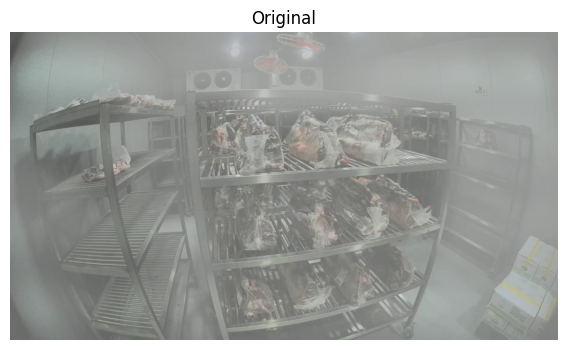

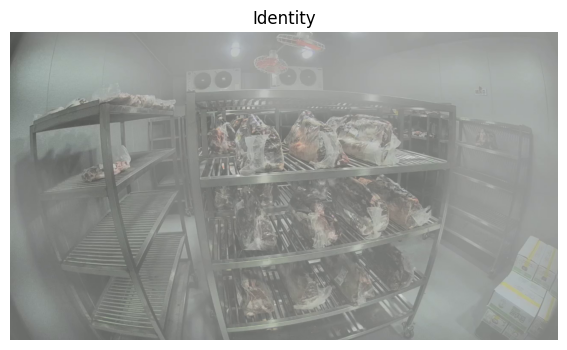

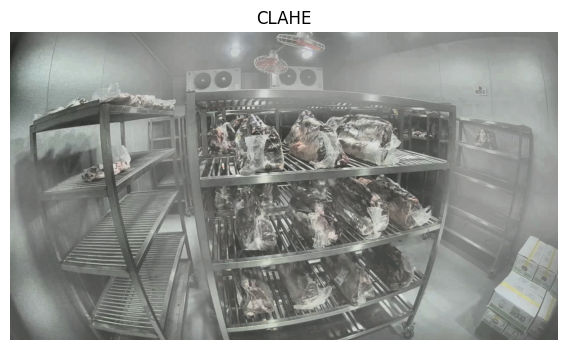

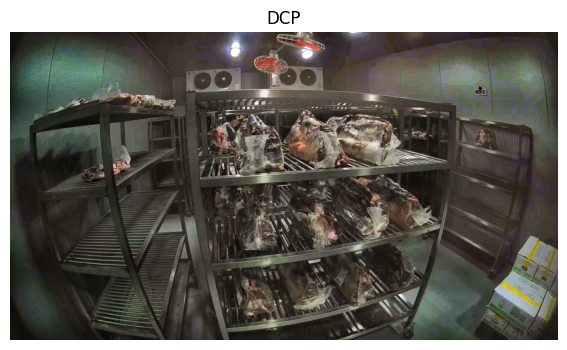

In [26]:
# [호환성 체크 5]
# 원본 이미지와 각 dehazing 결과를 시각적으로 비교한다.
# 이 셀의 목적은 정량 평가가 아니라,
# "정말 이미지가 변했는지", "출력이 깨지지 않았는지",
# "Identity는 원본 그대로인지"를 눈으로 빠르게 확인하는 것이다.
#
# Visually compare the original image and each dehazing result.
# The purpose of this cell is not quantitative evaluation,
# but a quick visual sanity check:
# "Did the image actually change?",
# "Is the output broken?",
# and "Does Identity really return the original image?"

import matplotlib.pyplot as plt
import cv2

def show_bgr(img, title):

    # OpenCV의 BGR 이미지를 matplotlib에서 보기 위해 RGB로 변환해서 출력한다.
    # Convert an OpenCV BGR image to RGB
    # so that it can be displayed correctly with matplotlib.
    plt.figure(figsize=(8, 4))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

show_bgr(rgb, "Original")
show_bgr(out_identity, "Identity")
show_bgr(out_clahe, "CLAHE")
show_bgr(out_dcp, "DCP")